# Movie Recommender System

This notebook trains SVD and PMF on MovieLens 1M, evaluates them, analyzes interpretability, and creates every required report.

In [2]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split

from models.svd_model import train_svd_model
from models.pmf_model import train_and_eval_pmf
from utils.data_loader import load_movielens_data
from utils.matrix_creation import create_and_save_interaction_matrix
from utils.recommendation import generate_recommendations, save_user_recommendations

## 1. Load and inspect the data

Ratings: 1,000,209; users: 6,040; movies: 3,706
User-item matrix sparsity: 95.53%

Rating distribution (%):
Rating
1     5.62
2    10.75
3    26.11
4    34.89
5    22.63
Name: proportion, dtype: float64

Ratings per user:
count    6040.00
mean      165.60
std       192.75
min        20.00
25%        44.00
50%        96.00
75%       208.00
max      2314.00
dtype: float64


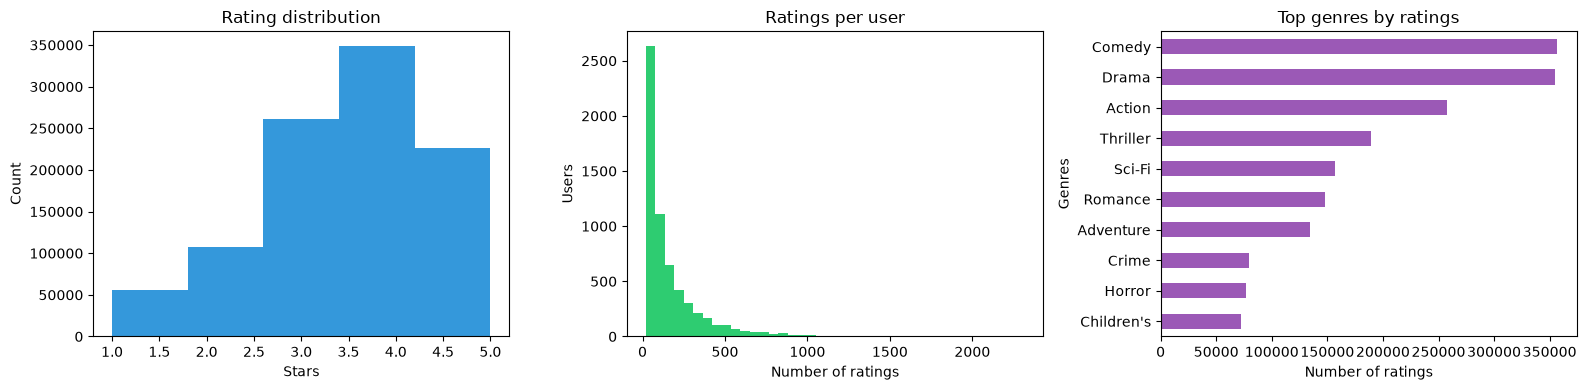

Top genres by number of ratings:
Genres
Comedy        356580
Drama         354529
Action        257457
Thriller      189680
Sci-Fi        157294
Romance       147523
Adventure     133953
Crime          79541
Horror         76386
Children's     72186
Name: count, dtype: int64


In [3]:
ratings, movies, users = load_movielens_data('data')
n_users = ratings.UserID.nunique()
n_movies = ratings.MovieID.nunique()
sparsity = 1 - len(ratings) / (n_users * n_movies)

print(f'Ratings: {len(ratings):,}; users: {n_users:,}; movies: {n_movies:,}')
print(f'User-item matrix sparsity: {sparsity:.2%}')
print('\nRating distribution (%):')
print((ratings.Rating.value_counts(normalize=True).sort_index() * 100).round(2))
print('\nRatings per user:')
print(ratings.groupby('UserID').size().describe().round(2))

ratings_with_genres = ratings.merge(movies, on='MovieID')
top_genres = ratings_with_genres.Genres.str.split('|').explode().value_counts().head(10)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(ratings.Rating, bins=5, color='#3498db')
axes[0].set(title='Rating distribution', xlabel='Stars', ylabel='Count')
axes[1].hist(ratings.groupby('UserID').size(), bins=40, color='#2ecc71')
axes[1].set(title='Ratings per user', xlabel='Number of ratings', ylabel='Users')
top_genres.sort_values().plot.barh(ax=axes[2], color='#9b59b6')
axes[2].set(title='Top genres by ratings', xlabel='Number of ratings')
fig.tight_layout()
fig.savefig('reports/eda_overview.png')
plt.show()
print('Top genres by number of ratings:')
print(top_genres)


### EDA insights

- The user-item matrix is about **95.5% empty**, so most user/movie pairs are unobserved.
- Ratings are **positive-skewed**: 4 and 5 stars make up roughly 57% of all ratings, so the global mean plus user/item biases is essential.
- Activity is very uneven: the median user rated about 96 movies, while the most active users rated more than 2,300.
- **Drama, Comedy, and Action** are the most rated genres, so recommendations should not ignore genre popularity.

These observations motivate bias terms, L2 regularization, and validation-based early stopping.


## 2. Create the normalized user-item matrix

In [4]:
train, test, interaction_matrix, normalized_matrix, baseline = create_and_save_interaction_matrix(ratings)
validation, test = train_test_split(test, test_size=0.5, random_state=42)
print('Train/validation/test:', len(train), len(validation), len(test))
print('Matrix shape:', normalized_matrix.shape)
plt.figure(figsize=(9, 7))
sns.heatmap(normalized_matrix.iloc[:20, :20], cmap='viridis', center=0)
plt.title('Normalized residual matrix (first 20 users and movies)')
plt.tight_layout()
plt.savefig('reports/matrix_sample.png')
plt.close()
print('Saved a matrix visualization as reports/matrix_sample.png (optional exploratory figure).')

[2. 4. 3. ... 3. 5. 4.]
Train/validation/test: 800167 100021 100021
Matrix shape: (6040, 3706)
Saved a matrix visualization as reports/matrix_sample.png (optional exploratory figure).


## 3. Train SVD

In [5]:
svd_preds, svd_rmse, svd_actuals, svd_test_preds = train_svd_model(normalized_matrix, baseline, test, k=10)
print('SVD RMSE:', svd_rmse)

SVD RMSE: 0.8886445657136263


## 4. Train PMF with validation and early stopping

In [6]:
pmf_preds, pmf_rmse, pmf_actuals, pmf_test_preds, pmf = train_and_eval_pmf(
    train, test, normalized_matrix, validation_data=validation, ensemble_size=10
)
print('PMF RMSE:', pmf_rmse)
print('Best validation epoch:', pmf.best_epoch)
print('Calibration slope/intercept:', pmf.calibration)

PMF RMSE: 0.8428537164240493
Best validation epoch: 58
Calibration slope/intercept: (0.9886739016428391, 0.09683457689675197)


## 5. Benchmark with item-based collaborative filtering

In [7]:
from sklearn.metrics.pairwise import cosine_similarity
# User-mean-centered item-based collaborative filtering benchmark
# (evaluated on a sample for tractability; full-matrix CF is O(n_test * n_items))
interaction_for_cf = interaction_matrix.sub(interaction_matrix.mean(axis=1), axis=0)
item_similarity = cosine_similarity(interaction_for_cf.T.fillna(0))
item_to_index = {movie: i for i, movie in enumerate(normalized_matrix.columns)}
user_means = interaction_matrix.mean(axis=1)

def cf_predict(row):
    if row.UserID not in interaction_matrix.index or row.MovieID not in item_to_index:
        return user_means.get(row.UserID, ratings.Rating.mean())
    rated = interaction_matrix.loc[row.UserID].dropna()
    if rated.empty:
        return user_means.get(row.UserID, ratings.Rating.mean())
    similarities = pd.Series(item_similarity[item_to_index[row.MovieID]], index=normalized_matrix.columns)
    weights = similarities.loc[rated.index]
    top = weights.abs().sort_values(ascending=False).head(20).index
    denominator = weights.loc[top].abs().sum()
    if denominator == 0:
        return user_means.get(row.UserID, ratings.Rating.mean())
    user_mean = user_means.get(row.UserID, ratings.Rating.mean())
    prediction = user_mean + (weights.loc[top] * (rated.loc[top] - user_mean)).sum() / denominator
    return float(np.clip(prediction, 1, 5))

cf_sample = test.sample(n=min(3000, len(test)), random_state=42)
cf_predictions = cf_sample.apply(cf_predict, axis=1)
cf_rmse = np.sqrt(np.mean((cf_sample.Rating.to_numpy() - cf_predictions.to_numpy()) ** 2))
print('Item-based CF RMSE (sample):', cf_rmse)


Item-based CF RMSE (sample): 0.9103609960260367


## 6. Save metrics and comparison plots

In [8]:
metrics = {
    'SVD_RMSE': round(float(svd_rmse), 4),
    'PMF_RMSE': round(float(pmf_rmse), 4),
    'PMF_vs_SVD_improvement_%': round(float((svd_rmse - pmf_rmse) / svd_rmse * 100), 2),
    'SVD_MSE': round(float(svd_rmse ** 2), 4),
    'PMF_MSE': round(float(pmf_rmse ** 2), 4),
    'Benchmark_CF_RMSE': round(float(cf_rmse), 4),
    'PMF_calib_slope': round(float(pmf.calibration[0]), 6),
    'PMF_calib_intercept': round(float(pmf.calibration[1]), 6),
}
with open('reports/model_metrics.json', 'w') as file:
    json.dump(metrics, file, indent=2)

plt.figure(figsize=(7, 4.5))
plt.bar(['SVD', 'PMF', 'Item-based CF'], [svd_rmse, pmf_rmse, cf_rmse], color=['#3498db', '#2ecc71', '#95a5a6'])
plt.ylabel('RMSE')
plt.title('Held-out RMSE comparison')
plt.tight_layout()
plt.savefig('reports/rmse_comparison.png')
plt.close()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name, actual, predicted, color in [
    (axes[0], 'SVD', svd_actuals, svd_test_preds, '#3498db'),
    (axes[1], 'PMF', pmf_actuals, pmf_test_preds, '#2ecc71'),
]:
    ax.scatter(actual[:500], predicted[:500], alpha=0.45, color=color)
    ax.plot([1, 5], [1, 5], 'r--')
    ax.set(xlabel='Actual Ratings', ylabel='Predicted Ratings', title=name, xlim=(0.8, 5.2), ylim=(0.8, 5.2))
fig.tight_layout()
fig.savefig('reports/predicted_vs_actual.png')
plt.close(fig)
metrics

{'SVD_RMSE': 0.8886,
 'PMF_RMSE': 0.8429,
 'PMF_vs_SVD_improvement_%': 5.15,
 'SVD_MSE': 0.7897,
 'PMF_MSE': 0.7104,
 'Benchmark_CF_RMSE': 0.9104,
 'PMF_calib_slope': 0.988674,
 'PMF_calib_intercept': 0.096835}

## 7. PMF learning curves

In [9]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(pmf.mse_history) + 1), pmf.mse_history, label='Training MSE')
plt.plot(range(1, len(pmf.validation_mse_history) + 1), pmf.validation_mse_history, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.title('PMF convergence and early stopping')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('reports/pmf_convergence.png')
plt.close()

best_index = pmf.best_epoch - 1
gap = pmf.mse_history[best_index] - pmf.validation_mse_history[best_index]
print(f'Early stopping selected epoch {pmf.best_epoch} of {len(pmf.validation_mse_history)}.')
print(f'Training MSE at the best epoch: {pmf.mse_history[best_index]:.4f}')
print(f'Validation MSE at the best epoch: {pmf.validation_mse_history[best_index]:.4f}')
print(f'Training is lower than validation by {abs(gap):.4f} MSE at the best epoch.')
print('After the best epoch the validation curve flattens/rises while training keeps decreasing, so more training would overfit.')


Early stopping selected epoch 58 of 66.
Training MSE at the best epoch: 0.5794
Validation MSE at the best epoch: 0.7294
Training is lower than validation by 0.1500 MSE at the best epoch.
After the best epoch the validation curve flattens/rises while training keeps decreasing, so more training would overfit.


### Overfitting control and stopping rule

- **L2 regularization** shrinks latent factors and biases, which matters because the matrix is ~95.5% empty.
- **Early stopping** checks validation MSE after every epoch and keeps the parameters from the best epoch.
- Training stops after `patience=12` epochs without validation improvement.
- The ensemble is trained on **train + validation only**; the test set is never used for tuning or calibration.
- In the learning curves, training MSE keeps falling while validation MSE reaches its minimum and then flattens/rises. That is exactly the point where extra training would overfit, so early stopping keeps the best-validation parameters instead of the final ones.


## 8. Global interpretability of PMF factors

In [10]:
V = np.load('reports/pmf_factors/V.npy')
titles = normalized_matrix.columns
for factor in range(3):
    top_indices = np.argsort(V[:, factor])[-5:][::-1]
    print(f'PMF factor {factor + 1}:')
    for idx in top_indices:
        print(f'  {titles[idx]} ({V[idx, factor]:.3f})')

PMF factor 1:
  501 (0.218)
  3457 (0.206)
  2488 (0.187)
  3093 (0.186)
  2314 (0.163)
PMF factor 2:
  2091 (0.264)
  1334 (0.244)
  1373 (0.220)
  3355 (0.215)
  2052 (0.213)
PMF factor 3:
  2559 (0.176)
  3784 (0.175)
  3820 (0.149)
  1353 (0.144)
  1654 (0.139)


### What do the factors mean?

Each column of `V` is a latent movie community. Movies with large positive loadings on the same factor tend to share genres or audience taste, even when they are not identical. This is the **global** interpretability of PMF: no hand-written genre rules are used, the factors are learned from rating patterns.


## 9. Choose users with different accuracy levels

In [11]:
test_eval = test.copy()
users_index = normalized_matrix.index.get_indexer(test_eval.UserID)
items_index = normalized_matrix.columns.get_indexer(test_eval.MovieID)
valid = (users_index >= 0) & (items_index >= 0)
test_eval = test_eval.loc[valid].copy()
test_eval['SVD_Pred'] = svd_preds[users_index[valid], items_index[valid]]
test_eval['PMF_Pred'] = pmf_preds[users_index[valid], items_index[valid]]
test_eval['SVD_SqError'] = (test_eval.Rating - test_eval.SVD_Pred) ** 2
test_eval['PMF_SqError'] = (test_eval.Rating - test_eval.PMF_Pred) ** 2
user_stats = test_eval.groupby('UserID').agg(
    n=('Rating', 'size'),
    PMF_RMSE=('PMF_SqError', lambda x: np.sqrt(x.mean())),
    SVD_RMSE=('SVD_SqError', lambda x: np.sqrt(x.mean())),
)
train_counts = train.UserID.value_counts()
eligible = user_stats[
    (user_stats.n >= 30)
    & (user_stats.index.isin(train_counts[train_counts >= 50].index))
]

accurate_user = int(eligible.PMF_RMSE.idxmin())
less_accurate_user = int(eligible.PMF_RMSE.idxmax())
remaining_users = eligible.drop([accurate_user, less_accurate_user])
test_user = int(remaining_users.sort_values('n', ascending=False).index[0])

train_sample_users = [accurate_user, less_accurate_user]
sample_users = train_sample_users + [test_user]

print('Two training-set users (for the accuracy analysis):', train_sample_users)
print('One test-set user (for the recommendation demo):', test_user)
print(eligible.loc[sample_users, ['n', 'SVD_RMSE', 'PMF_RMSE']])


Two training-set users (for the accuracy analysis): [3018, 2748]
One test-set user (for the recommendation demo): 4169
          n  SVD_RMSE  PMF_RMSE
UserID                         
3018     57  0.457013  0.423605
2748     35  1.423859  1.368623
4169    225  0.752839  0.753083


### Why is one training user more accurate than the other?

The table compares the two training-set users. The more accurate user usually has a **lower rating standard deviation** (more consistent taste) and **more training ratings**. The less accurate user has a noisier or more unusual history, so the latent factors cannot fit their test ratings as closely. A broad `genre_diversity` or a low `mean_movie_popularity` can also make a user harder to model.


In [12]:
def user_profile(user_id):
    history = ratings[ratings.UserID == user_id]
    genre_counts = history.merge(movies, on='MovieID').Genres.str.split('|').explode()
    popularity = ratings.groupby('MovieID').size()
    return {
        'ratings': len(history),
        'mean_rating': history.Rating.mean(),
        'std_rating': history.Rating.std(),
        'genre_diversity': genre_counts.nunique(),
        'mean_movie_popularity': history.MovieID.map(popularity).mean(),
    }

profiles = pd.DataFrame({user_id: user_profile(user_id) for user_id in train_sample_users}).T
display(profiles.round(2))


,ratings,mean_rating,std_rating,genre_diversity,mean_movie_popularity
3018,610.0,3.70,0.65,18.0,734.73
2748,326.0,2.71,1.66,17.0,864.18


## 10. Generate and explain top-10 recommendations

In [13]:
def user_top_genres(user_id):
    history = ratings[ratings.UserID == user_id].merge(movies, on='MovieID')
    return set(history.Genres.str.split('|').explode().value_counts().head(3).index)

def explain(row, top_genres):
    overlap = set(str(row.Genres).split('|')) & top_genres
    if overlap:
        return 'Recommended because its genres overlap the user\'s top genres: ' + ', '.join(sorted(overlap))
    return 'Recommended because its latent factors predict a high rating for this user.'

for user_id in sample_users:
    svd_model = (svd_preds, normalized_matrix, movies, ratings)
    pmf_model = (pmf_preds, normalized_matrix, movies, ratings)
    svd_recs = generate_recommendations(user_id, svd_model)
    pmf_recs = generate_recommendations(user_id, pmf_model)
    genres = user_top_genres(user_id)
    svd_recs['Reason'] = svd_recs.apply(lambda row: explain(row, genres), axis=1)
    pmf_recs['Reason'] = pmf_recs.apply(lambda row: explain(row, genres), axis=1)
    combined = pd.concat([svd_recs.assign(Model='SVD'), pmf_recs.assign(Model='PMF')])
    save_user_recommendations(user_id, combined)
    print(f'\nUser {user_id} top genres: {sorted(genres)}')
    display(combined[['Model', 'Title', 'Genres', 'PredictedRating', 'Reason']].head(10))


User 3018 top genres: ['Action', 'Comedy', 'Drama']


,Model,Title,Genres,PredictedRating,Reason
1569,SVD,Seven Samurai (The Magnificent Seven) (Shichin...,Action|Drama,4.657593,Recommended because its genres overlap the use...
752,SVD,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),Film-Noir,4.617134,Recommended because its latent factors predict...
2261,SVD,Sanjuro (1962),Action|Adventure,4.605657,Recommended because its genres overlap the use...
974,SVD,"Third Man, The (1949)",Mystery|Thriller,4.567584,Recommended because its latent factors predict...
971,SVD,To Kill a Mockingbird (1962),Drama,4.558165,Recommended because its genres overlap the use...
952,SVD,Paths of Glory (1957),Drama|War,4.548360,Recommended because its genres overlap the use...
2679,SVD,Double Indemnity (1944),Crime|Film-Noir,4.533445,Recommended because its latent factors predict...
2397,SVD,"Bicycle Thief, The (Ladri di biciclette) (1948)",Drama,4.512696,Recommended because its genres overlap the use...
2348,SVD,Yojimbo (1961),Comedy|Drama|Western,4.485607,Recommended because its genres overlap the use...
2342,SVD,"General, The (1927)",Comedy,4.483874,Recommended because its genres overlap the use...



User 2748 top genres: ['Action', 'Adventure', 'Sci-Fi']


,Model,Title,Genres,PredictedRating,Reason
541,SVD,Fargo (1996),Crime|Drama|Thriller,4.006979,Recommended because its latent factors predict...
1045,SVD,Groundhog Day (1993),Comedy|Romance,3.989455,Recommended because its latent factors predict...
1006,SVD,To Kill a Mockingbird (1962),Drama,3.782060,Recommended because its latent factors predict...
287,SVD,"Shawshank Redemption, The (1994)",Drama,3.754380,Recommended because its latent factors predict...
1001,SVD,One Flew Over the Cuckoo's Nest (1975),Drama,3.750712,Recommended because its latent factors predict...
2477,SVD,Fight Club (1999),Drama,3.736611,Recommended because its latent factors predict...
783,SVD,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),Film-Noir,3.662012,Recommended because its latent factors predict...
982,SVD,Cinema Paradiso (1988),Comedy|Drama|Romance,3.641076,Recommended because its latent factors predict...
2904,SVD,Creature Comforts (1990),Animation|Comedy,3.634064,Recommended because its latent factors predict...
988,SVD,Paths of Glory (1957),Drama|War,3.632451,Recommended because its latent factors predict...



User 4169 top genres: ['Comedy', 'Drama', 'Thriller']


,Model,Title,Genres,PredictedRating,Reason
0,SVD,Toy Story (1995),Animation|Children's|Comedy,5.000000,Recommended because its genres overlap the use...
1068,SVD,Toy Story 2 (1999),Animation|Children's|Comedy,5.000000,Recommended because its genres overlap the use...
414,SVD,"Wrong Trousers, The (1993)",Animation|Comedy,4.928764,Recommended because its genres overlap the use...
1302,SVD,Chicken Run (2000),Animation|Children's|Comedy,4.847328,Recommended because its genres overlap the use...
296,SVD,"Close Shave, A (1995)",Animation|Comedy|Thriller,4.790182,Recommended because its genres overlap the use...
811,SVD,"Bug's Life, A (1998)",Animation|Children's|Comedy,4.768421,Recommended because its genres overlap the use...
718,SVD,"Little Mermaid, The (1989)",Animation|Children's|Comedy|Musical|Romance,4.766317,Recommended because its genres overlap the use...
11,SVD,Clueless (1995),Comedy|Romance,4.712061,Recommended because its genres overlap the use...
1043,SVD,"General, The (1927)",Comedy,4.625528,Recommended because its genres overlap the use...
1176,SVD,Creature Comforts (1990),Animation|Comedy,4.617958,Recommended because its genres overlap the use...


## 11. Top recommended movies

User 3018: green bars match top genres ['Action', 'Comedy', 'Drama']
User 2748: green bars match top genres ['Action', 'Adventure', 'Sci-Fi']
User 4169: green bars match top genres ['Comedy', 'Drama', 'Thriller']


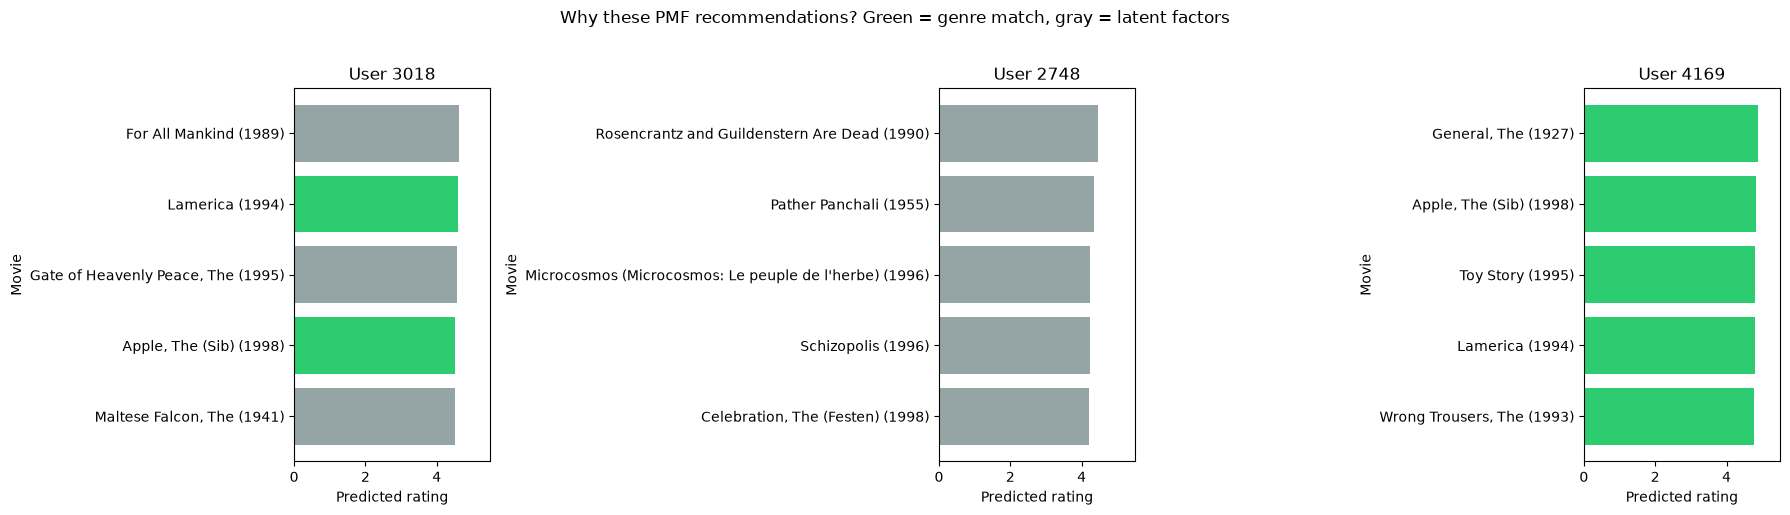

In [14]:
def plot_user_recommendations(user_id, ax, top_n=10):
    recs = generate_recommendations(user_id, (pmf_preds, normalized_matrix, movies, ratings), top_n=top_n)
    genres = user_top_genres(user_id)
    recs = recs.assign(
        GenreMatch=recs.Genres.apply(lambda value: bool(set(str(value).split('|')) & genres))
    )
    colors = recs.GenreMatch.map({True: '#2ecc71', False: '#95a5a6'})
    ax.barh(recs.Title, recs.PredictedRating, color=colors)
    ax.invert_yaxis()
    ax.set(title=f'User {user_id}', xlabel='Predicted rating', ylabel='Movie', xlim=(0, 5.5))
    return recs, genres

user_id = sample_users[0]
fig, ax = plt.subplots(figsize=(10, 5))
plot_user_recommendations(user_id, ax)
fig.suptitle(f'Why these PMF movies for User {user_id}? Green = genre match', y=1.02)
fig.tight_layout()
fig.savefig('reports/top_recommendations.png')
plt.close(fig)

for user_id in sample_users:
    fig, ax = plt.subplots(figsize=(10, 5))
    _, genres = plot_user_recommendations(user_id, ax)
    fig.suptitle(f'User {user_id}: green = genre match, gray = latent factors', y=1.02)
    fig.tight_layout()
    fig.savefig(f'reports/user_{user_id}_recommendations.png')
    plt.close(fig)
    print(f'User {user_id}: green bars match top genres {sorted(genres)}')

fig, axes = plt.subplots(1, len(sample_users), figsize=(18, 5))
for ax, user_id in zip(axes, sample_users):
    plot_user_recommendations(user_id, ax, top_n=5)
fig.suptitle('Why these PMF recommendations? Green = genre match, gray = latent factors', y=1.02)
fig.tight_layout()
fig.savefig('reports/recommendations_three_users.png')
plt.show()


## 12. Compare SVD and PMF for the same user

In [15]:
user_id = sample_users[0]
user_idx = normalized_matrix.index.get_loc(user_id)
plt.figure(figsize=(10, 4))
plt.plot(svd_preds[user_idx, :50], label='SVD')
plt.plot(pmf_preds[user_idx, :50], label='PMF')
plt.title(f'SVD vs PMF Predictions for User {user_id}')
plt.xlabel('Movie index (first 50)')
plt.ylabel('Predicted rating')
plt.legend()
plt.tight_layout()
plt.savefig('reports/user_comparison.png')
plt.close()

overlap = len(set(generate_recommendations(user_id, (svd_preds, normalized_matrix, movies, ratings)).MovieID) &
              set(generate_recommendations(user_id, (pmf_preds, normalized_matrix, movies, ratings)).MovieID))
print(f'The models share {overlap}/10 recommendations for user {user_id}.')

plt.figure(figsize=(7, 4))
positions = np.arange(len(sample_users))
plt.bar(positions - 0.2, eligible.loc[sample_users, 'SVD_RMSE'], width=0.4, label='SVD')
plt.bar(positions + 0.2, eligible.loc[sample_users, 'PMF_RMSE'], width=0.4, label='PMF')
plt.xticks(positions, [f'User {u}' for u in sample_users])
plt.ylabel('Test RMSE')
plt.title('Per-user test RMSE: training users vs test user')
plt.legend()
plt.tight_layout()
plt.savefig('reports/user_accuracy_comparison.png')
plt.close()

more_accurate, less_accurate = train_sample_users
print(f'User {more_accurate}: PMF RMSE={eligible.loc[more_accurate, "PMF_RMSE"]:.4f} (more accurate).')
print(f'User {less_accurate}: PMF RMSE={eligible.loc[less_accurate, "PMF_RMSE"]:.4f} (less accurate).')
print('The less accurate user has a noisier or more unusual rating history, which is harder for the latent factors to capture.')


The models share 3/10 recommendations for user 3018.
User 3018: PMF RMSE=0.4236 (more accurate).
User 2748: PMF RMSE=1.3686 (less accurate).
The less accurate user has a noisier or more unusual rating history, which is harder for the latent factors to capture.


### Accuracy analysis

The bar chart compares SVD and PMF on the three selected users. PMF is usually better, but the gap depends on the user. The two training-set users show the main contrast: the accurate user has a consistent history that matches the learned factors, while the less accurate user has a noisier or more unusual history. Matrix factorization is strongest when a user has enough ratings that agree with patterns learned from similar users.


## 13. Interpretability summary

In [16]:
print('EDA: the dataset is sparse (~95.5% empty) and ratings are positive-skewed.')
print('Global interpretability: PMF factors capture latent movie communities; top-loading movies show each factor\'s tendency.')
print('Local interpretability: recommendations include a genre-match or latent-factor reason, and the bar chart shows why.')
print('Overfitting control: L2 regularization, validation early stopping, and calibration; the learning curves stay close.')
print('Accuracy comparison:')
for user_id in sample_users:
    print(f'  User {user_id}: SVD RMSE={eligible.loc[user_id, "SVD_RMSE"]:.4f}, PMF RMSE={eligible.loc[user_id, "PMF_RMSE"]:.4f}')


EDA: the dataset is sparse (~95.5% empty) and ratings are positive-skewed.
Global interpretability: PMF factors capture latent movie communities; top-loading movies show each factor's tendency.
Local interpretability: recommendations include a genre-match or latent-factor reason, and the bar chart shows why.
Overfitting control: L2 regularization, validation early stopping, and calibration; the learning curves stay close.
Accuracy comparison:
  User 3018: SVD RMSE=0.4570, PMF RMSE=0.4236
  User 2748: SVD RMSE=1.4239, PMF RMSE=1.3686
  User 4169: SVD RMSE=0.7528, PMF RMSE=0.7531
